# Finding and fitting two planets with Gaia astrometry and radial velocities

This notebook
1. simulates Gaia DR5 epoch astrometry and three radial-velocity (RV) datasets of a star with two giant planets,
2. searches for planets in the RVs alone (best fit, plots, MCMC and corner plots),
3. searches for planets in the astrometry and RVs jointly (best fit, plots, MCMC and corner plots), and
4. derives the posterior of the planets' mutual inclination.

It needs `gaiamockplus`, `emcee` and `corner`. The two MCMCs take about 7 minutes in total.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import emcee
import corner
import gaiamockplus as gmp
from gaiamockplus import gaiamock

%config InlineBackend.figure_format = 'retina'

c_funcs = gaiamock.read_in_C_functions()  # compiled functions used by gaiamock's routines
rng = np.random.default_rng(29)           # random numbers for the simulation (reproducible)
M_JUP = 1/1047.57                         # Jupiter mass in Msun

## 1. Simulate the astrometry and the RVs

The system is that of notebook 02 (a Sun-like star at 50 pc, with planets at 1.2 and 7 yr), but with less massive planets (6 and 4 $M_\mathrm{J}$), so that the astrometric signals are smaller. It is dynamically stable: $\beta/\beta_\mathrm{crit} = 1.20 > 1$ by the Hill-stability criterion of Gladman (1993), in the form of Barnes & Greenberg (2006), and the orbits are nearly coplanar (mutual inclination 6.4°).

As in notebook 03, the RVs come from three instruments, each with its own systemic velocity and formal uncertainties, and include 3 m/s of jitter added in quadrature. To constrain two planets, there are more RVs (45), spread over 19 yr (about 2.7 orbits of the outer planet).

In [2]:
# the star: a Sun-like star at 50 pc
m_star = 1.0               # Msun
parallax = 20.0            # mas
phot_g_mean_mag = 8.1      # G magnitude of such a star at 50 pc
ra, dec = 200.0, 35.0      # deg
pmra, pmdec = -25.0, 15.0  # mas/yr

# the planets (b: inner, c: outer)
planets = [dict(period=1.2*365.25, Tp=200.0, ecc=0.1, Omega=np.radians(100.0), inc=np.radians(50.0), w=np.radians(30.0), m_planet=6*M_JUP),
           dict(period=7.0*365.25, Tp=900.0, ecc=0.2, Omega=np.radians(105.0), inc=np.radians(55.0), w=np.radians(120.0), m_planet=4*M_JUP)]
names = ['b', 'c']

# Gaia astrometry
ast_data = gmp.predict_astrometry_planets(ra=ra, dec=dec, parallax=parallax, pmra=pmra, pmdec=pmdec, m_star=m_star,
                                          planets=planets, phot_g_mean_mag=phot_g_mean_mag, data_release='dr5',
                                          c_funcs=c_funcs, rng=rng)
t_ast_yr, psi, plx_factor, ast_obs, ast_err = ast_data

# three RV datasets: number of RVs, formal uncertainty (km/s), and time range (yr, relative to the reference epoch)
n_rv = [10, 15, 20]
rv_err_set = [0.007, 0.010, 0.010]
time_ranges = [(-10, -2), (-4, 4), (1, 9)]
gamma = np.array([-12.405, -12.380, -12.420])  # systemic velocity of each dataset (km/s)
jitter = 0.003                                 # km/s

t_rvs_yr = np.concatenate([np.sort(rng.uniform(*r, n)) for r, n in zip(time_ranges, n_rv)])
rv_dataset = np.repeat([0, 1, 2], n_rv)        # the dataset of each RV
rv_err = np.repeat(rv_err_set, n_rv)           # formal uncertainties
rv = (gmp.rv_planets_model(t_rvs_yr, m_star, planets, gamma, c_funcs, rv_dataset=rv_dataset)
      + np.sqrt(rv_err**2 + jitter**2)*rng.normal(0, 1, len(t_rvs_yr)))
rv_data = (t_rvs_yr, rv, rv_err)

a0_true, K_true = gmp.get_planet_a0_mas(m_star, planets, parallax), gmp.get_planet_K_kms(m_star, planets)
print(f'astrometry: {len(t_ast_yr)} transits, median uncertainty {np.median(ast_err):.3f} mas; RVs: {len(rv)} in {len(n_rv)} datasets')
for name, planet, a0, K in zip(names, planets, a0_true, K_true):
    print(f'planet {name}: P = {planet["period"]/365.25:.1f} yr, a0 = {a0:.3f} mas, K = {1e3*K:.1f} m/s')

astrometry: 204 transits, median uncertainty 0.080 mas; RVs: 45 in 3 datasets
planet b: P = 1.2 yr, a0 = 0.129 mas, K = 123.1 m/s
planet c: P = 7.0 yr, a0 = 0.279 mas, K = 49.6 m/s


## 2. Search for planets in the RVs alone

Without `n_planets`, `fit_rv_planets` runs the same blind search as `fit_astrometry_planets` in notebook 02, adding planets while each lowers $-2\ln L$ by more than 50. The jitter of each dataset is fitted by maximum likelihood.

In [3]:
res_rv = gmp.fit_rv_planets(*rv_data, rv_dataset=rv_dataset, m_star=m_star)

print(f"planets found: {res_rv['n_planets']}; -2 ln L for 0, 1, 2 planets:", np.round(res_rv['chi2_history'], 1))
print(f"the best three-planet model would lower -2 ln L by only {res_rv['rejected_candidate']['delta_chi2']:.1f} < 50")
for name, planet, fit, K in zip(names, planets, res_rv['planets'], K_true):
    rows = [('P [yr]', planet['period']/365.25, fit['period']/365.25, fit['sig_period']/365.25),
            ('e', planet['ecc'], fit['ecc'], fit['sig_ecc']),
            ('K [m/s]', 1e3*K, 1e3*fit['K'], 1e3*fit['sig_K']),
            ('w [deg]', np.degrees(planet['w']), np.degrees(fit['w']), np.degrees(fit['sig_w'])),
            ('m_p sin i [M_Jup]', planet['m_planet']*np.sin(planet['inc'])/M_JUP, fit['m_sini']/M_JUP, fit['sig_m_sini']/M_JUP)]
    print(f"\nplanet {name} (-2 ln L increase if removed: {fit['delta_chi2']:.0f}) {'true':>6s} {'fit':>16s}")
    for label, true, value, sigma in rows:
        print(f'{label:36s} {true:8.3f} {value:8.3f} +/- {sigma:.3f}')
print('\njitter [m/s]: true 3 for each dataset; fit', np.round(1e3*res_rv['jitter'], 1))

planets found: 2; -2 ln L for 0, 1, 2 planets: [ -92.2 -187.  -297. ]
the best three-planet model would lower -2 ln L by only 23.4 < 50

planet b (-2 ln L increase if removed: 184)   true              fit
P [yr]                                  1.200    1.200 +/- 0.001
e                                       0.100    0.117 +/- 0.020
K [m/s]                               123.127  121.445 +/- 2.497
w [deg]                                30.000   22.078 +/- 8.677
m_p sin i [M_Jup]                       4.596    4.522 +/- 0.091

planet c (-2 ln L increase if removed: 110)   true              fit
P [yr]                                  7.000    6.931 +/- 0.067
e                                       0.200    0.169 +/- 0.049
K [m/s]                                49.579   49.882 +/- 2.462
w [deg]                               120.000  135.386 +/- 19.319
m_p sin i [M_Jup]                       3.277    3.304 +/- 0.170

jitter [m/s]: true 3 for each dataset; fit [0.  0.  4.6]


As in notebook 02, each planet's signal is shown with the other planet's best-fit signal subtracted (and each dataset's systemic velocity); error bars are the formal uncertainty and the fitted jitter in quadrature. The bottom panel shows the residuals of the full model. The same function is used for the joint fit below.

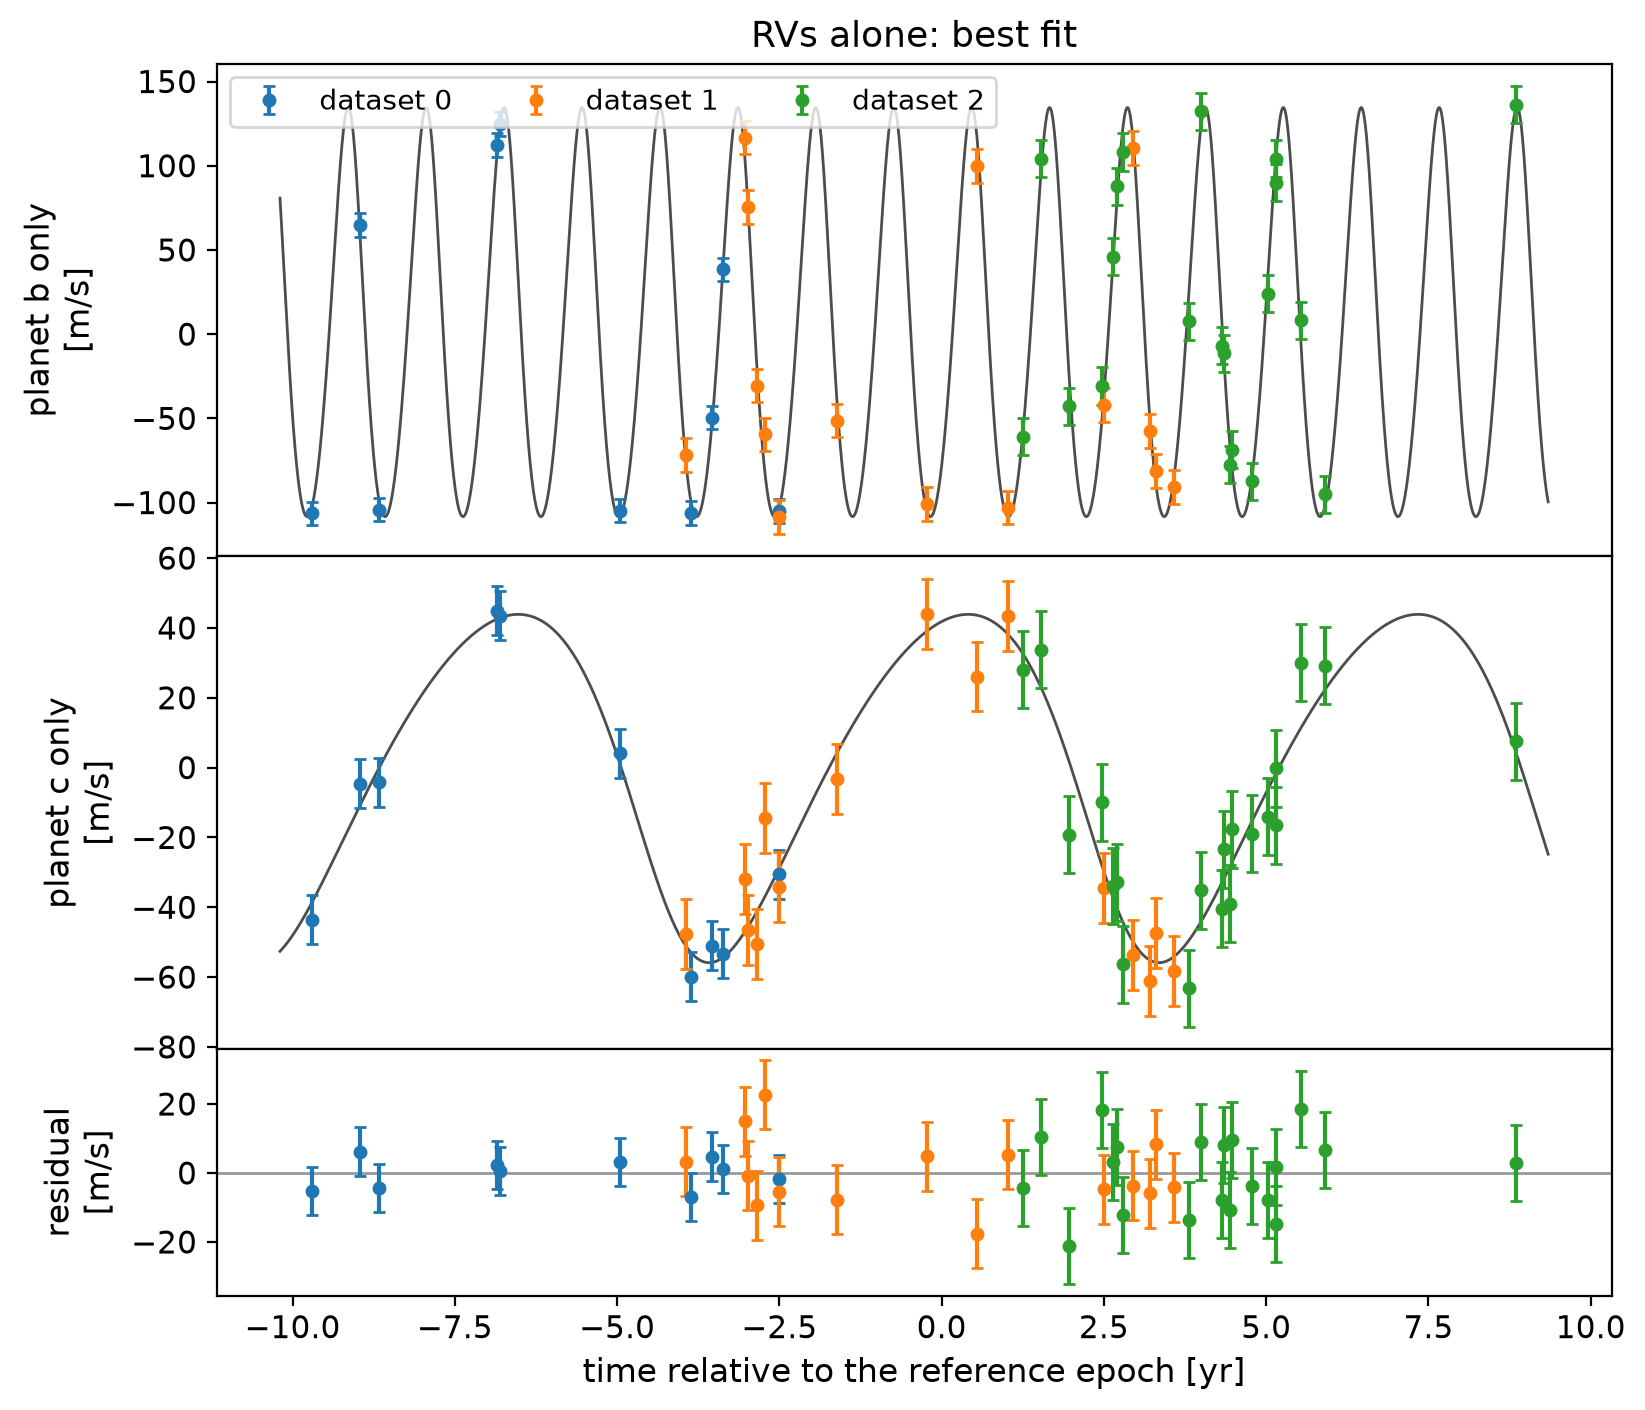

In [4]:
def plot_rvs(res, title):
    '''Each planet's RV signal (data with the other planet and the systemic velocities subtracted) and the residuals, for a fit result.'''
    t_grid = np.linspace(t_rvs_yr.min() - 0.5, t_rvs_yr.max() + 0.5, 5000)
    _, curves = gmp.rv_planets_model(t_grid, m_star, res['model_planets'], 0.0, c_funcs, return_components=True)
    model, comps = gmp.rv_planets_model(t_rvs_yr, m_star, res['model_planets'], res['gamma'], c_funcs, rv_dataset=rv_dataset, return_components=True)
    err = np.sqrt(rv_err**2 + res['jitter'][rv_dataset]**2)
    fig, axes = plt.subplots(3, 1, figsize=(9, 8), sharex=True, gridspec_kw=dict(height_ratios=[2, 2, 1], hspace=0))
    for i in range(2):
        axes[i].plot(t_grid, 1e3*curves[i], color='0.3', lw=1, zorder=0)
        for k in range(len(n_rv)):
            on = rv_dataset == k
            axes[i].errorbar(t_rvs_yr[on], 1e3*(rv[on] - res['gamma'][k] - comps[1 - i][on]), 1e3*err[on], fmt='o', ms=4, capsize=2,
                             color=f'C{k}', label=f'dataset {k}')
        axes[i].set_ylabel(f'planet {names[i]} only\n[m/s]', fontsize=12)
    for k in range(len(n_rv)):
        on = rv_dataset == k
        axes[2].errorbar(t_rvs_yr[on], 1e3*(rv[on] - model[on]), 1e3*err[on], fmt='o', ms=4, capsize=2, color=f'C{k}')
    axes[2].axhline(0, color='0.6', lw=1, zorder=0)
    axes[2].set_ylabel('residual\n[m/s]', fontsize=12)
    axes[2].set_xlabel('time relative to the reference epoch [yr]', fontsize=12)
    axes[0].set_title(title, fontsize=13)
    axes[0].legend(fontsize=10, ncol=3, loc='upper left')
    for ax in axes:
        ax.tick_params(labelsize=11)
    plt.show()

plot_rvs(res_rv, 'RVs alone: best fit')

### MCMC for the RVs

As in notebook 03, the linear parameters (the systemic velocities, and $K\cos\omega$, $K\sin\omega$ of each planet) are integrated out, so the walkers sample $P$, $e$ and $\phi_p$ of each planet, followed by the jitter of each dataset: 9 parameters instead of 16. The priors are uniform, with each $\phi_p$ within $\pi$ of its best-fit value (as in notebook 01), $P_b < P_c$ (so that the walkers cannot swap the planets) and the jitter between 0 and 50 m/s. The corner plots show the central 99% of each parameter. The slowest parameter is the outer planet's $\phi_p$, which at its modest eccentricity is less well constrained than its orbital phase.

In [5]:
best = dict(zip(res_rv['theta_names'], res_rv['theta']))  # best-fit values by name
phi0_rv = np.array([best['phi_p_0'], best['phi_p_1']])

def log_prior_rv(theta):
    P, e, phis, jit = theta[0:6:3], theta[1:6:3], theta[2:6:3], theta[6:]
    if (np.all((10 < P) & (P < 1e4)) and P[0] < P[1] and np.all((0 <= e) & (e < 1)) and np.all(np.abs(phis - phi0_rv) < np.pi)
            and np.all((0 <= jit) & (jit < 0.05))):
        return 0.0
    return -np.inf

def log_prob_rv(theta):
    lp = log_prior_rv(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp + gmp.log_likelihood_rv_planets(theta, *rv_data, rv_dataset=rv_dataset)

nwalkers, nsteps = 40, 23000
p0 = gmp.initial_walkers(res_rv, nwalkers, log_prob=log_prior_rv, rng=rng)
np.random.seed(29)  # emcee draws its moves from numpy's global random state
sampler_rv = emcee.EnsembleSampler(nwalkers, p0.shape[1], log_prob_rv)
sampler_rv.run_mcmc(p0, nsteps, progress=True);

In [6]:
# convergence: the chain should be much longer than the autocorrelation time (tol=0: estimate it whatever the chain length)
names_rv = gmp.sampled_names(res_rv) + ['jitter_0', 'jitter_1', 'jitter_2']
tau = sampler_rv.get_autocorr_time(tol=0)
print('autocorrelation times [steps]:', ', '.join(f'{n} {t:.0f}' for n, t in zip(names_rv, tau)))
print(f'chain length / longest autocorrelation time = {nsteps/tau.max():.0f}')
burn, thin = int(5*tau.max()), int(tau.max()/2)  # discard the burn-in (5 autocorrelation times) and thin the chain
samples_rv = sampler_rv.get_chain(discard=burn, thin=thin, flat=True)
print(f'{len(samples_rv)} samples')
samples_rv = gmp.expand_marginal_samples(samples_rv, res_rv, rv_data=rv_data, rv_dataset=rv_dataset, rng=rng)  # all parameters, ordered like res_rv['theta']

autocorrelation times [steps]: period_0 140, ecc_0 141, phi_p_0 148, period_1 148, ecc_1 170, phi_p_1 197, jitter_0 155, jitter_1 171, jitter_2 135
chain length / longest autocorrelation time = 117
8960 samples


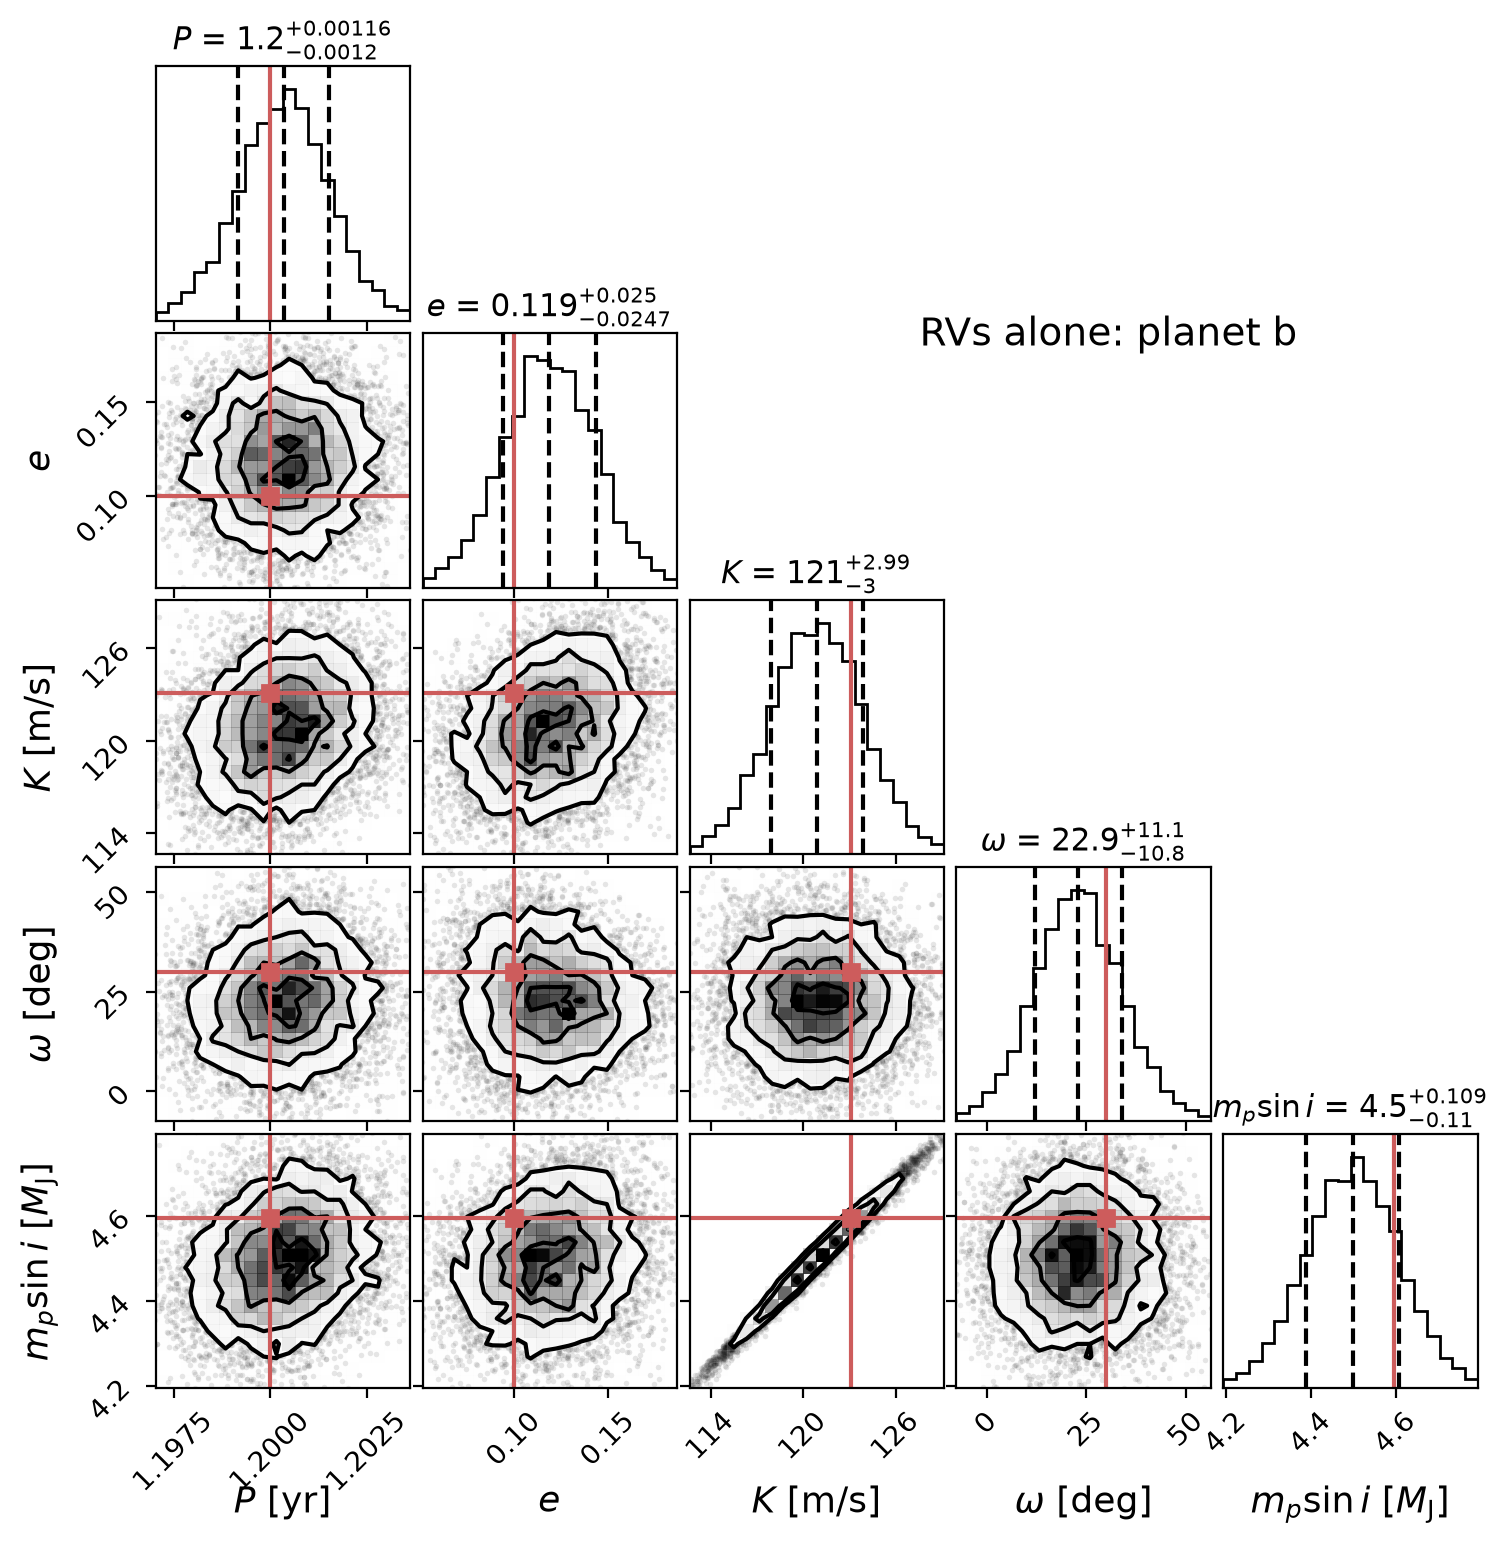

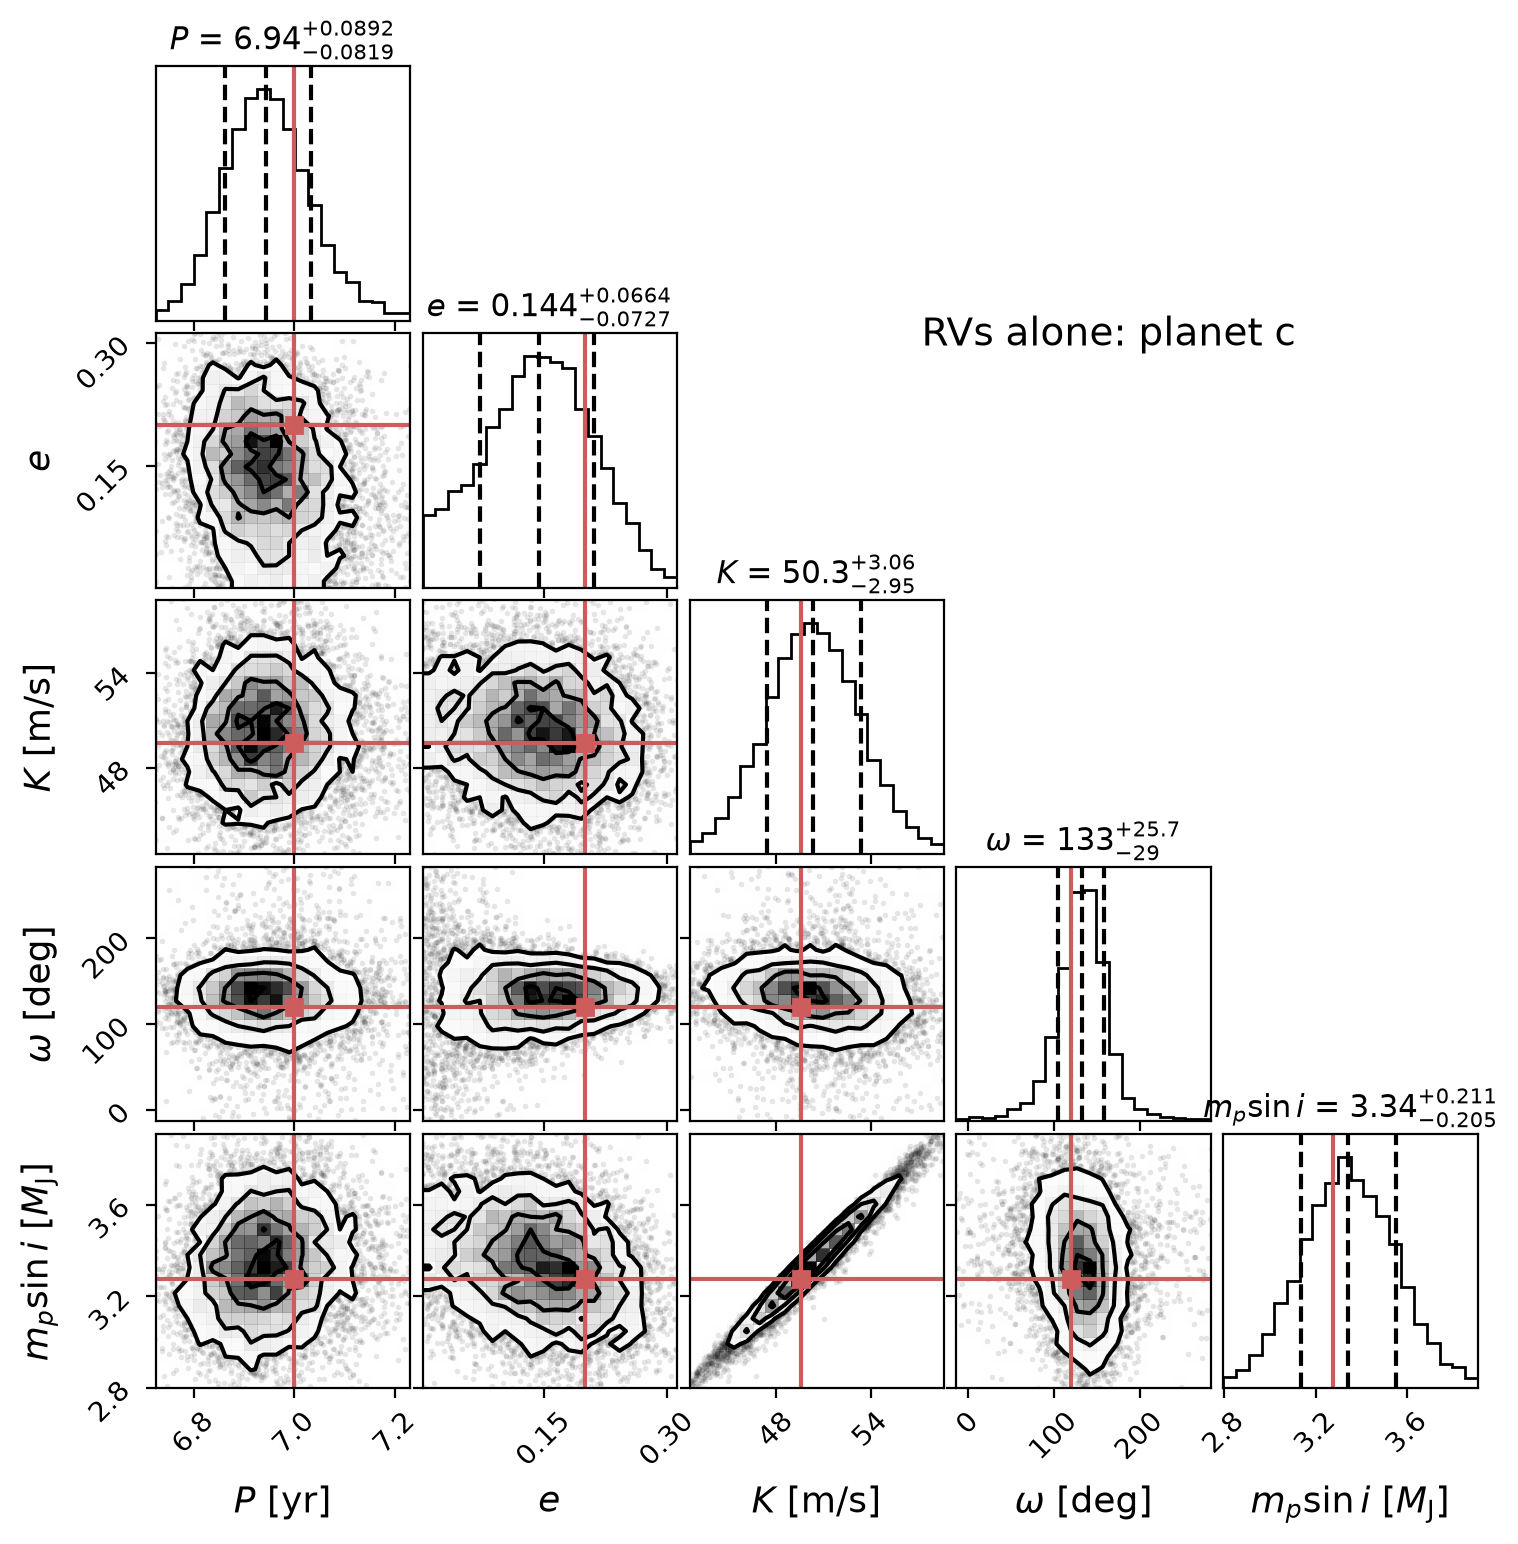

jitter [m/s] (true 3): dataset 0: 4.0 (+5.0 / -2.8), dataset 1: 6.0 (+4.7 / -4.0), dataset 2: 7.6 (+4.1 / -4.1)


In [7]:
msini_rv = []
for i, (planet, fit, K) in enumerate(zip(planets, res_rv['planets'], K_true)):
    k = 3 + 5*i  # this planet's parameters: P, e, phi_p, K cos(w), K sin(w)
    P_s, e_s, h_s, c_s = samples_rv[:, k], samples_rv[:, k + 1], samples_rv[:, k + 3], samples_rv[:, k + 4]
    K_s = np.hypot(h_s, c_s)
    w_s = fit['w'] + np.angle(np.exp(1j*(np.arctan2(c_s, h_s) - fit['w'])))  # w is an angle: keep it continuous around the best fit
    msini_rv.append(gmp.get_planet_m_sini(K_s, P_s, e_s, m_star))
    corner_samples = np.column_stack([P_s/365.25, e_s, 1e3*K_s, np.degrees(w_s), msini_rv[i]/M_JUP])
    labels = [r'$P$ [yr]', r'$e$', r'$K$ [m/s]', r'$\omega$ [deg]', r'$m_p\sin i$ [$M_\mathrm{J}$]']
    titles = [r'$P$', r'$e$', r'$K$', r'$\omega$', r'$m_p\sin i$']
    truths = [planet['period']/365.25, planet['ecc'], 1e3*K, np.degrees(planet['w']), planet['m_planet']*np.sin(planet['inc'])/M_JUP]
    fig = corner.corner(corner_samples, range=[0.99]*corner_samples.shape[1], labels=labels, titles=titles, truths=truths,
                        truth_color='indianred', quantiles=[0.16, 0.5, 0.84], show_titles=True, title_fmt='.3g', max_n_ticks=3,
                        labelpad=0.08, label_kwargs=dict(fontsize=13), title_kwargs=dict(fontsize=11))
    fig.set_size_inches(7.5, 7.5)
    fig.suptitle(f'RVs alone: planet {names[i]}', fontsize=14, x=0.72, y=0.8)
    plt.show()

lo, med, hi = np.percentile(1e3*samples_rv[:, 13:], [16, 50, 84], axis=0)
print('jitter [m/s] (true 3):', ', '.join(f'dataset {k}: {med[k]:.1f} (+{hi[k] - med[k]:.1f} / -{med[k] - lo[k]:.1f})' for k in range(3)))

## 3. Search for planets in the astrometry and RVs jointly

Without `n_planets`, `fit_astrometry_and_rv_planets` runs the blind search with both datasets (each planet's orbit shared, with separate astrometric and RV amplitudes), then fits the full physical model, in which each planet's RV semi-amplitude follows from its astrometric orbit. As in notebook 03, this gives the true masses and resolves the $(\Omega, \omega) \to (\Omega + \pi, \omega + \pi)$ ambiguity of astrometry alone, for each planet.

In [8]:
res_joint = gmp.fit_astrometry_and_rv_planets(*ast_data, *rv_data, rv_dataset=rv_dataset, m_star=m_star)

print(f"planets found: {res_joint['n_planets']}; consistency_delta = {res_joint['consistency_delta']:.1f}")
print(f"parallax [mas]: true {parallax:.3f}, fit {res_joint['parallax']:.3f} +/- {res_joint['sig_parallax']:.3f}")
for name, planet, fit, a0 in zip(names, planets, res_joint['planets'], a0_true):
    rows = [('P [yr]', planet['period']/365.25, fit['period']/365.25, fit['sig_period']/365.25),
            ('e', planet['ecc'], fit['ecc'], fit['sig_ecc']),
            ('a0 [mas]', a0, fit['a0_mas'], fit['sig_a0_mas']),
            ('m_p [M_Jup]', planet['m_planet']/M_JUP, fit['m_planet']/M_JUP, fit['sig_m_planet']/M_JUP),
            ('inc [deg]', np.degrees(planet['inc']), np.degrees(fit['inc']), np.degrees(fit['sig_inc'])),
            ('w [deg]', np.degrees(planet['w']), np.degrees(fit['w']), np.degrees(fit['sig_w'])),
            ('Omega [deg]', np.degrees(planet['Omega']), np.degrees(fit['Omega']), np.degrees(fit['sig_Omega']))]
    print(f"\nplanet {name}      {'true':>8s} {'fit':>16s}")
    for label, true, value, sigma in rows:
        print(f'{label:15s} {true:8.3f} {value:8.3f} +/- {sigma:.3f}')
print('\njitter [m/s]: fit', np.round(1e3*res_joint['jitter'], 1))

planets found: 2; consistency_delta = 0.6
parallax [mas]: true 20.000, fit 19.991 +/- 0.012

planet b          true              fit
P [yr]             1.200    1.201 +/- 0.001
e                  0.100    0.119 +/- 0.020
a0 [mas]           0.129    0.133 +/- 0.007
m_p [M_Jup]        6.000    6.200 +/- 0.330
inc [deg]         50.000   46.943 +/- 3.226
w [deg]           30.000   22.199 +/- 8.227
Omega [deg]      100.000  102.725 +/- 4.339

planet c          true              fit
P [yr]             7.000    6.951 +/- 0.051
e                  0.200    0.167 +/- 0.040
a0 [mas]           0.279    0.275 +/- 0.008
m_p [M_Jup]        4.000    3.970 +/- 0.124
inc [deg]         55.000   55.405 +/- 2.542
w [deg]          120.000  133.691 +/- 15.529
Omega [deg]      105.000  106.783 +/- 2.955

jitter [m/s]: fit [0.  0.  4.5]


The best-fit orbits on the sky, each with the other planet's best-fit signal subtracted (as in notebook 02), and the best-fit RVs. Planet b's astrometric orbit (0.13 mas) is smaller than the measurement errors: it is constrained by the many measurements together, and by the RVs.

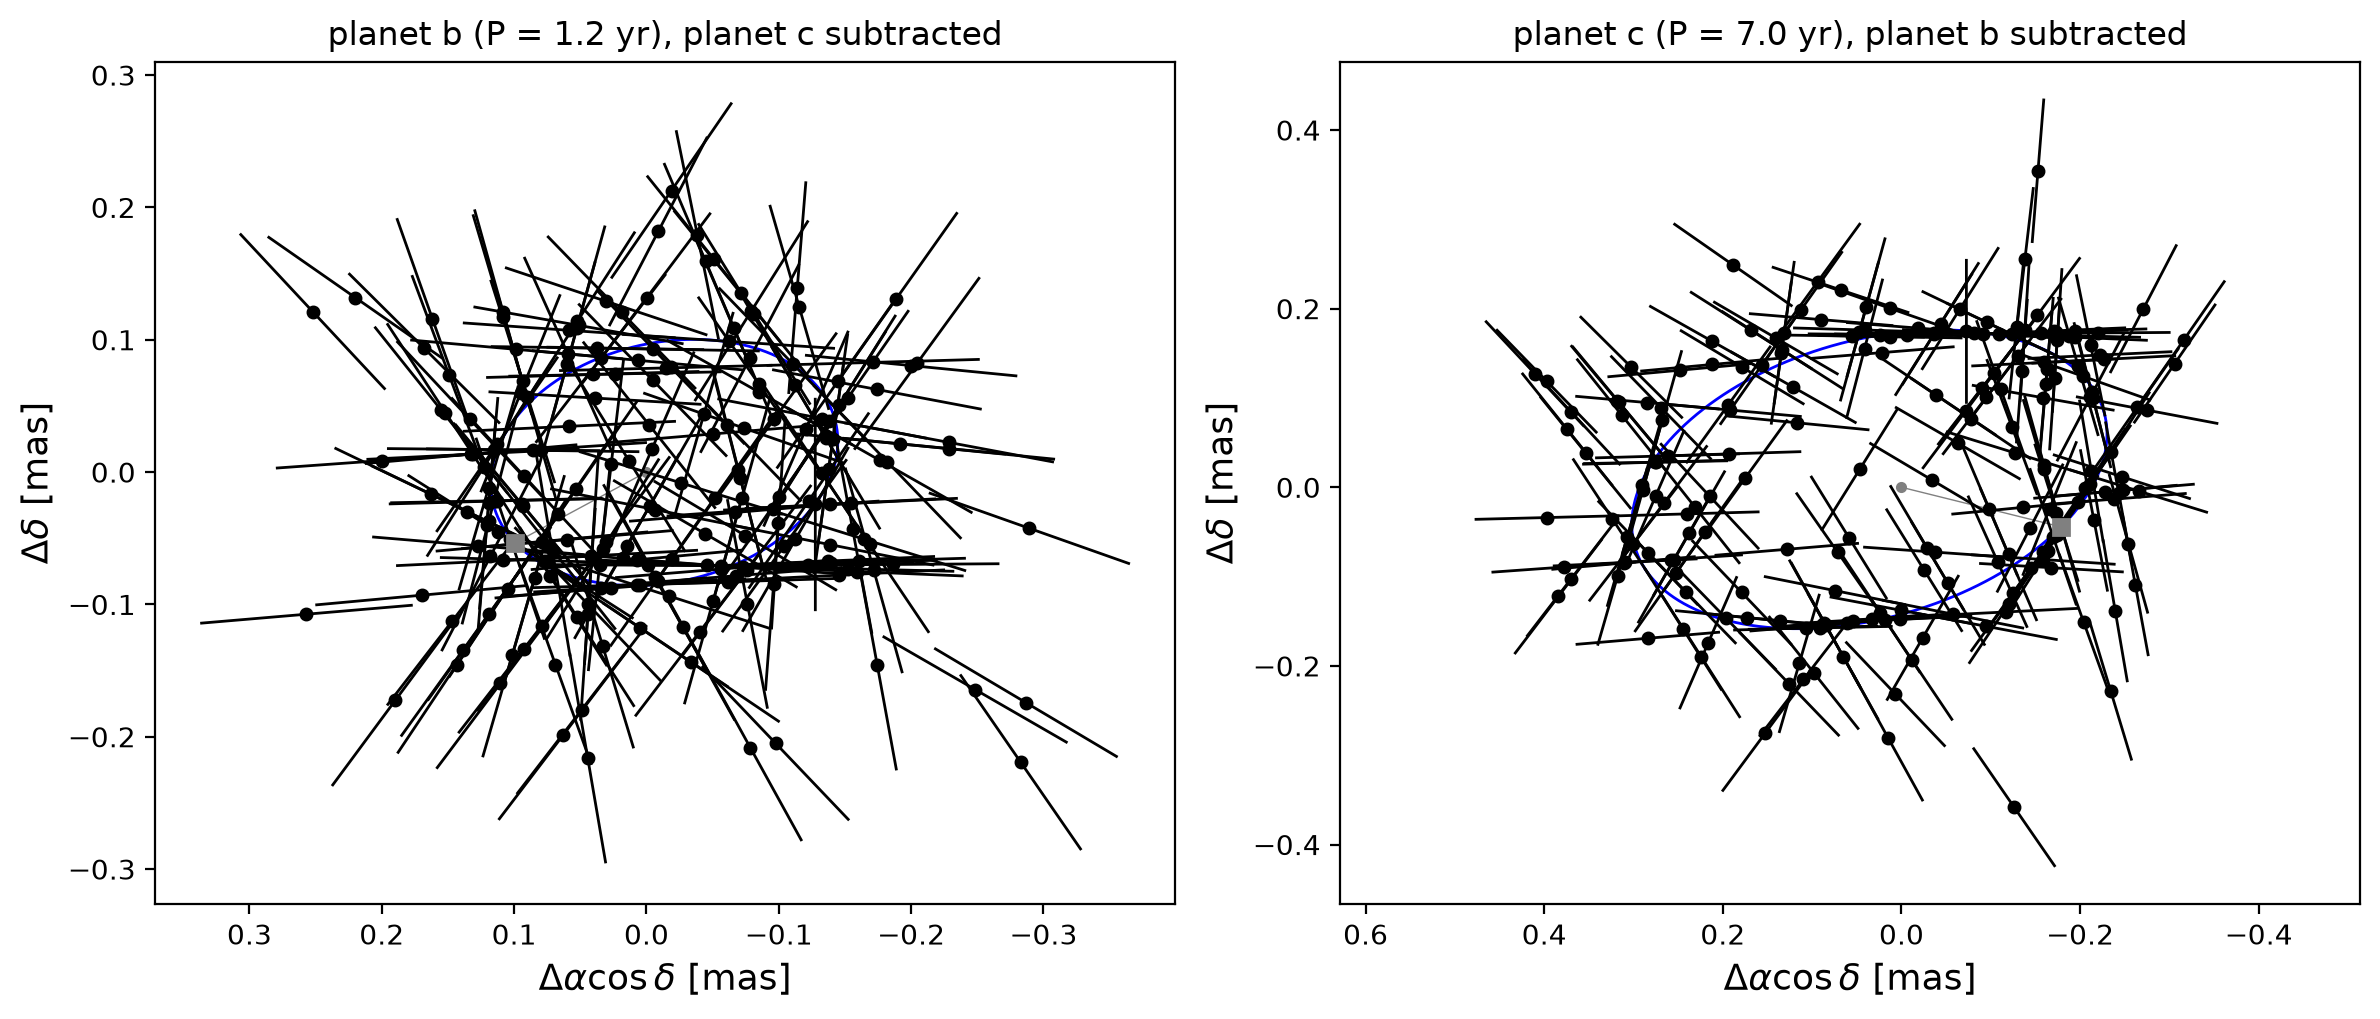

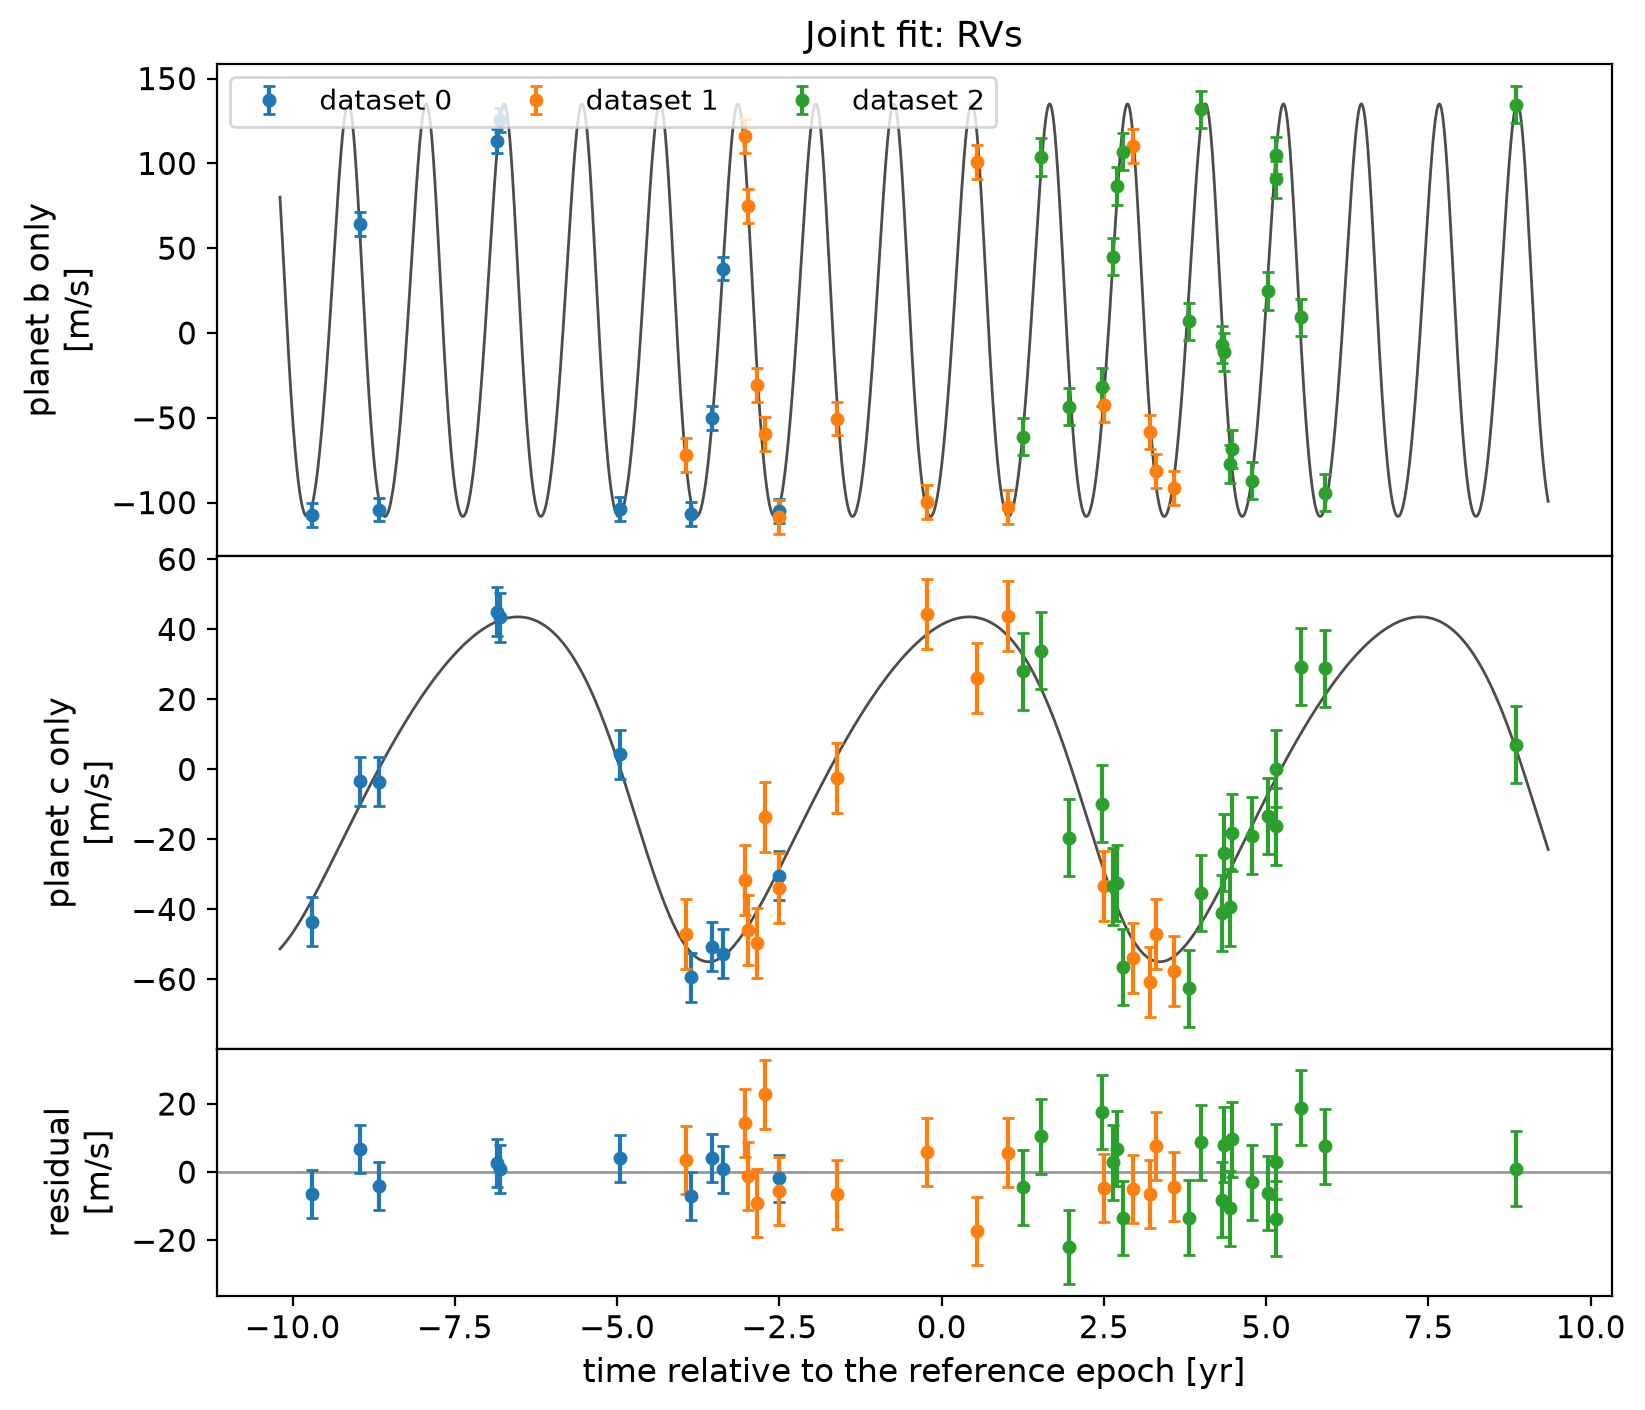

In [9]:
model, components = gmp.astrometry_planets_model(t_ast_yr, psi, plx_factor, res_joint['ra_off'], res_joint['dec_off'], res_joint['parallax'],
                                                 res_joint['pmra'], res_joint['pmdec'], m_star, res_joint['model_planets'], c_funcs,
                                                 return_components=True)
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
for i, (ax, fit) in enumerate(zip(axes, res_joint['planets'])):
    A, B, F, G = gmp.get_thiele_innes(fit['a0_mas'], fit['Omega'], fit['inc'], fit['w'])
    gaiamock.plot_2d_orbit_and_residuals(t_ast_yr, psi, plx_factor, ast_obs - components[1 - i], ast_err,
                                         period=fit['period'], ecc=fit['ecc'], Tp=fit['Tp'], delta_ra=res_joint['ra_off'],
                                         delta_dec=res_joint['dec_off'], parallax=res_joint['parallax'], pmra=res_joint['pmra'],
                                         pmdec=res_joint['pmdec'], A=A, B=B, F=F, G=G, data_release='dr5', c_funcs=c_funcs, ax=ax)
    ax.set_aspect('equal', adjustable='datalim')
    ax.set_xlabel(r'$\Delta\alpha\cos\delta$ [mas]', fontsize=13)
    ax.set_ylabel(r'$\Delta\delta$ [mas]', fontsize=13)
    ax.set_title(f'planet {names[i]} (P = {fit["period"]/365.25:.1f} yr), planet {names[1 - i]} subtracted', fontsize=12)
plt.tight_layout()
plt.show()

plot_rvs(res_joint, 'Joint fit: RVs')

### MCMC for the joint fit

As in notebook 03, the position offsets, proper motion and systemic velocities are integrated out, so the walkers sample the parallax, then $P$, $e$, $\phi_p$, $\Omega$, $i$, $\omega$, $a_0$ for each planet, followed by the jitter of each RV dataset and, as in notebook 01, an astrometric jitter, started at the value that makes the best fit's astrometric reduced $\chi^2$ 1: 19 parameters instead of 26. The priors are uniform, with $P_b < P_c$, $0 \le i \le \pi$, $a_0 > 0$ and the astrometric jitter below 0.5 mas; $\phi_p$, $\Omega$ and $\omega$ are kept within $\pi$ of their best-fit values. Again, the outer planet's $\phi_p$ and $\omega$ mix most slowly.

In [10]:
best = dict(zip(res_joint['theta_names'], res_joint['theta']))  # best-fit values by name
angles0 = np.array([best[f'{name}_{i}'] for i in range(2) for name in ('phi_p', 'Omega', 'w')])

def log_prior_joint(theta):
    P, e, inc, a0, jit, s = theta[1:15:7], theta[2:15:7], theta[5:15:7], theta[7:15:7], theta[15:18], theta[18]
    angles = theta[[3, 4, 6, 10, 11, 13]]  # phi_p, Omega, w of each planet
    if (0 < theta[0] and np.all((10 < P) & (P < 1e4)) and P[0] < P[1] and np.all((0 <= e) & (e < 1)) and np.all((0 <= inc) & (inc <= np.pi))
            and np.all(a0 > 0) and np.all(np.abs(angles - angles0) < np.pi) and np.all((0 <= jit) & (jit < 0.05)) and 0 <= s < 0.5):
        return 0.0
    return -np.inf

def log_prob_joint(theta):
    lp = log_prior_joint(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp + gmp.log_likelihood_astrometry_and_rv_planets(theta, t_ast_yr, psi, plx_factor, ast_obs, ast_err, *rv_data, rv_dataset=rv_dataset,
                                                            fit_ast_jitter=True)

s0 = gmp.estimate_astrometric_jitter(res_joint, ast_err)
print(f'starting astrometric jitter: {1e3*s0:.1f} microarcsec')
nwalkers, nsteps = 52, 55000
p0 = gmp.initial_walkers(res_joint, nwalkers, log_prob=log_prior_joint, ast_jitter=s0, rng=rng)
np.random.seed(29)
sampler_joint = emcee.EnsembleSampler(nwalkers, p0.shape[1], log_prob_joint)
sampler_joint.run_mcmc(p0, nsteps, progress=True);

starting astrometric jitter: 49.1 microarcsec


In [11]:
names_joint = gmp.sampled_names(res_joint) + ['jitter_0', 'jitter_1', 'jitter_2', 'ast_jitter']
tau = sampler_joint.get_autocorr_time(tol=0)
print('autocorrelation times [steps]:', ', '.join(f'{n} {t:.0f}' for n, t in zip(names_joint, tau)))
print(f'chain length / longest autocorrelation time = {nsteps/tau.max():.0f}')
burn, thin = int(5*tau.max()), int(tau.max()/2)
samples_joint = sampler_joint.get_chain(discard=burn, thin=thin, flat=True)
print(f'{len(samples_joint)} samples')
samples_joint = gmp.expand_marginal_samples(samples_joint, res_joint, ast_data=ast_data, rv_data=rv_data, rv_dataset=rv_dataset, fit_ast_jitter=True,
                                            rng=rng)  # all parameters, ordered like res_joint['theta'], then the jitters

autocorrelation times [steps]: parallax 382, period_0 411, ecc_0 375, phi_p_0 384, Omega_0 350, inc_0 418, w_0 383, a0_mas_0 415, period_1 380, ecc_1 451, phi_p_1 586, Omega_1 394, inc_1 360, w_1 582, a0_mas_1 359, jitter_0 485, jitter_1 438, jitter_2 391, ast_jitter 368
chain length / longest autocorrelation time = 94
9256 samples


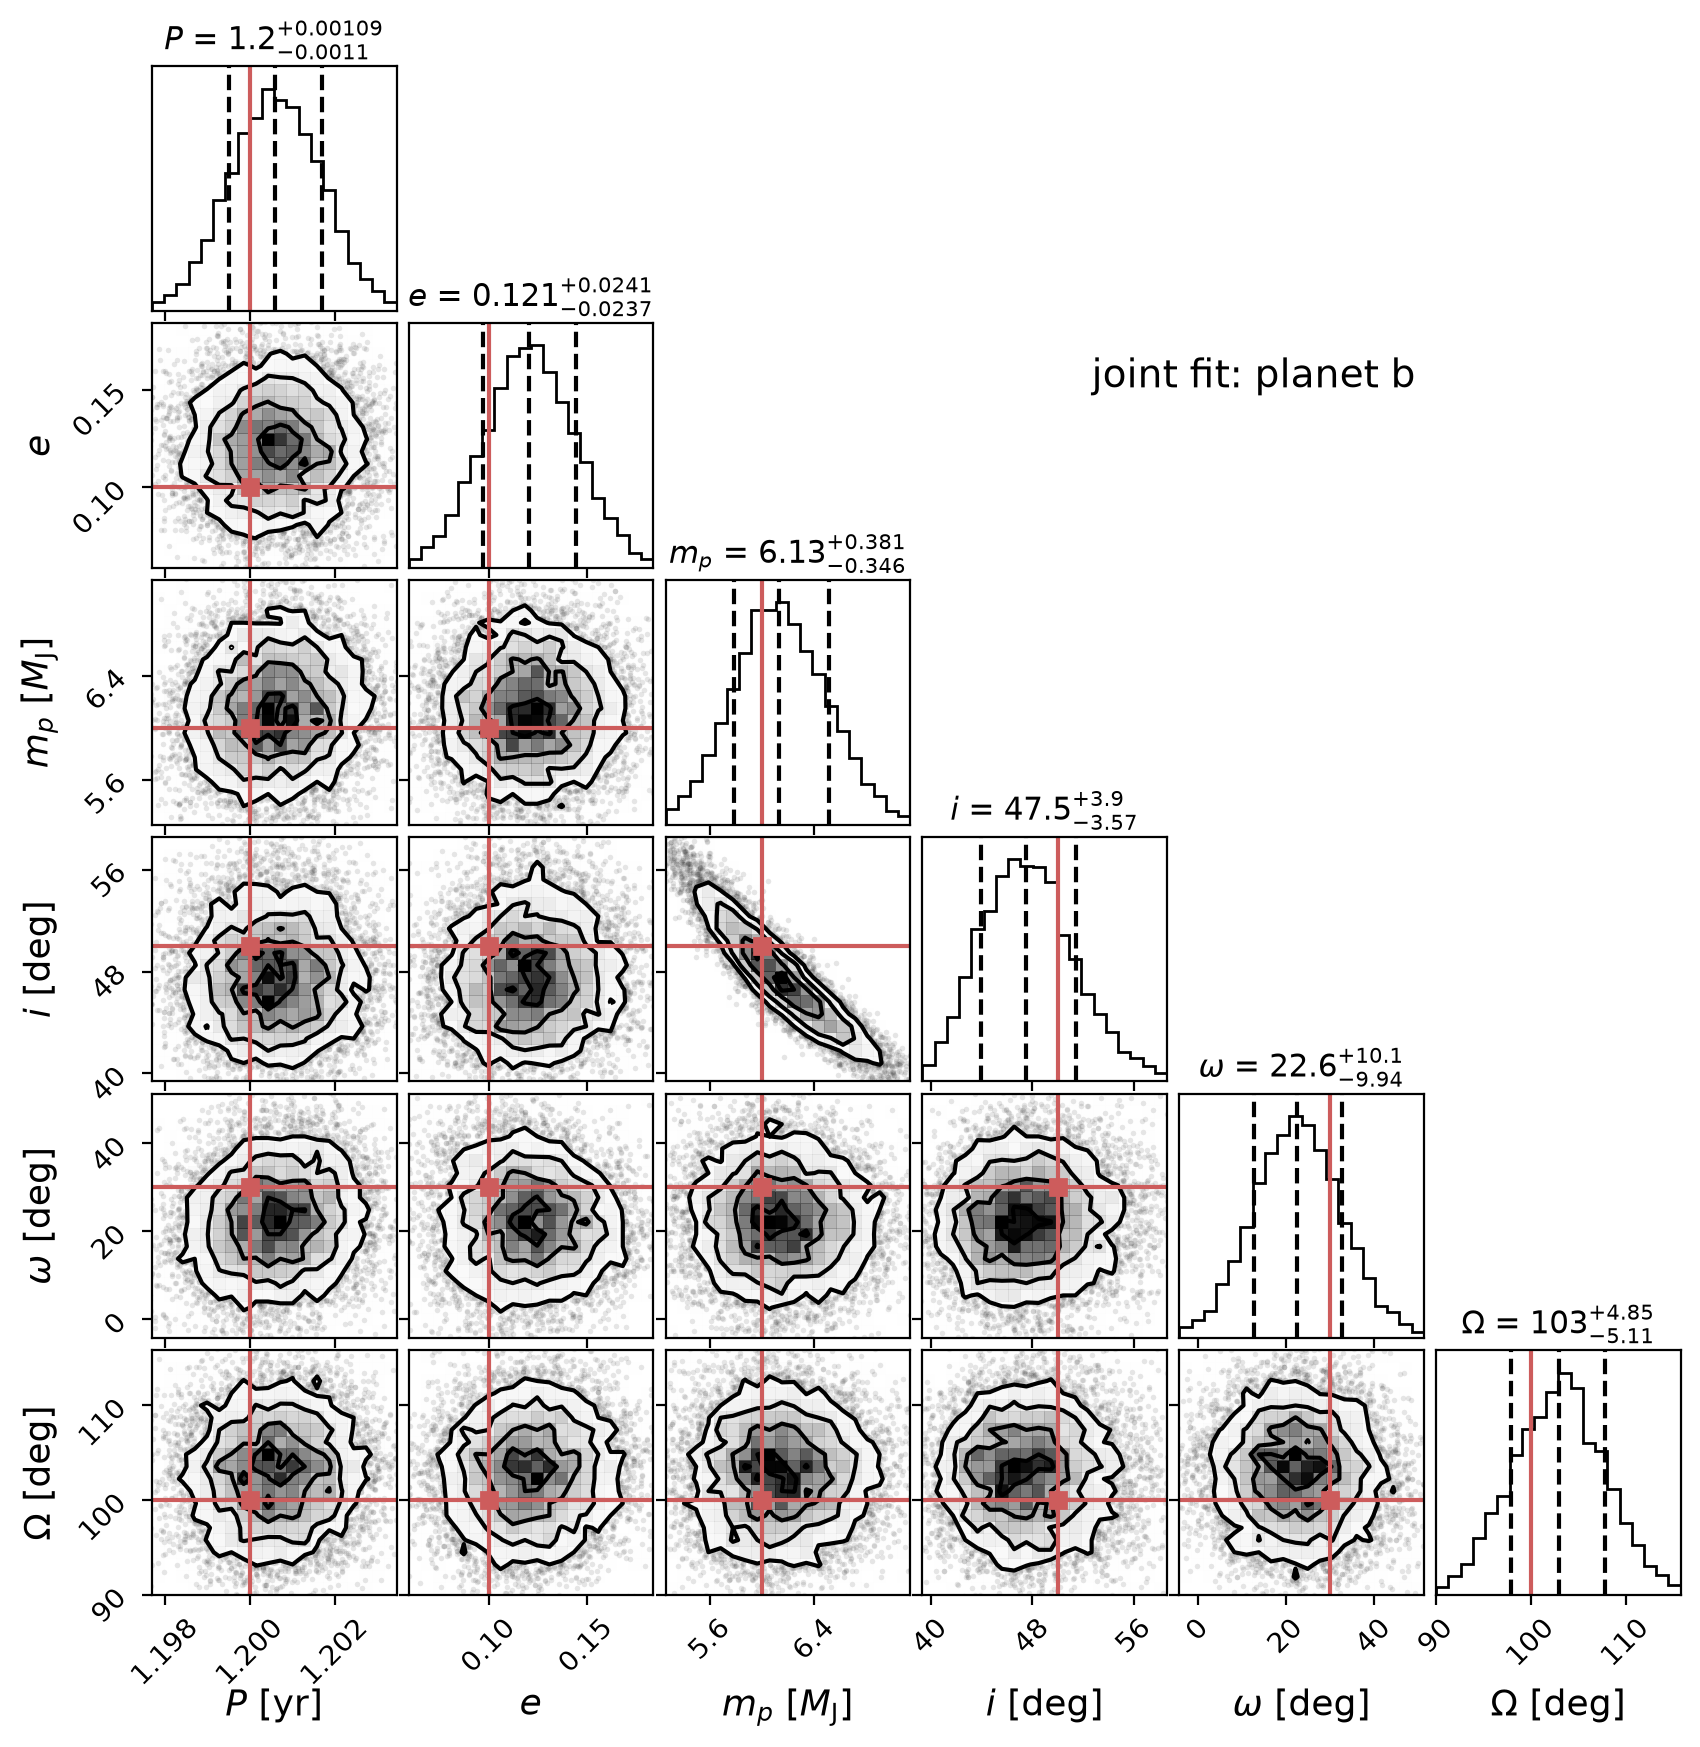

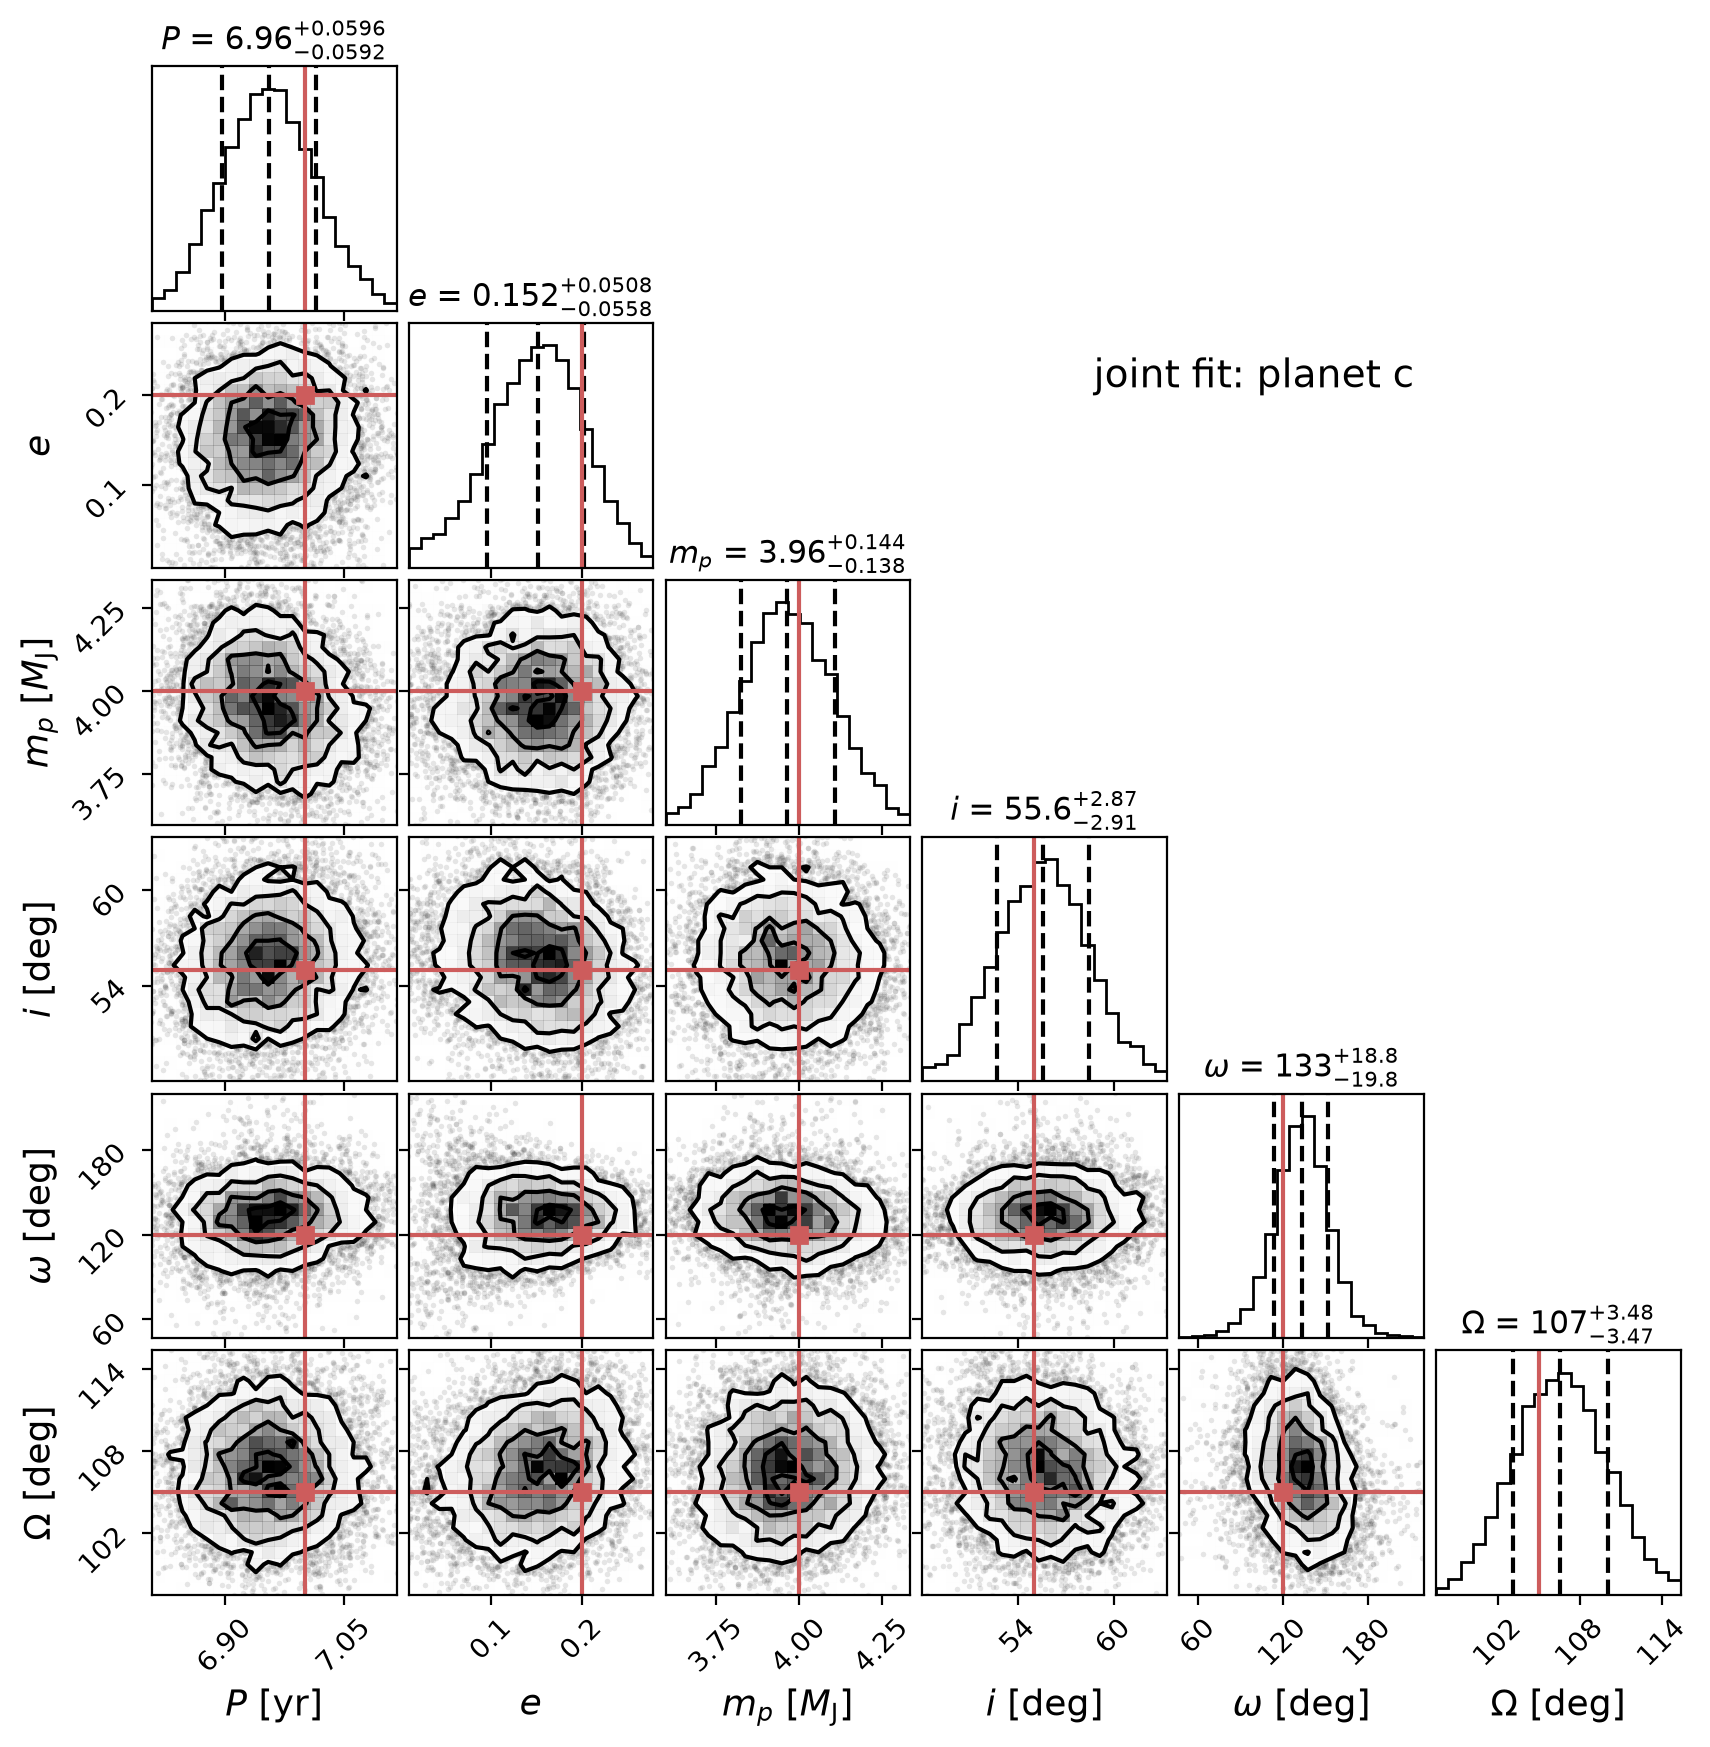

planet b: RVs alone m sin i = 4.50 +/- 0.11 M_Jup; joint m = 6.13 +/- 0.37 M_Jup (true 6)
planet c: RVs alone m sin i = 3.34 +/- 0.21 M_Jup; joint m = 3.96 +/- 0.14 M_Jup (true 4)
astrometric jitter: 44.2 (+9.7 / -10.9) microarcsec


In [12]:
plx_s = samples_joint[:, 2]
inc_s, Omega_s, m_joint = [], [], []
for i, (planet, fit) in enumerate(zip(planets, res_joint['planets'])):
    k = 5 + 7*i  # this planet's parameters: P, e, phi_p, Omega, inc, w, a0
    P_s, e_s, a0_s = samples_joint[:, k], samples_joint[:, k + 1], samples_joint[:, k + 6]
    inc_s.append(samples_joint[:, k + 4])
    Omega_s.append(fit['Omega'] + np.angle(np.exp(1j*(samples_joint[:, k + 3] - fit['Omega']))))  # keep the angles continuous
    w_s = fit['w'] + np.angle(np.exp(1j*(samples_joint[:, k + 5] - fit['w'])))                      # around the best fit
    m_joint.append(gmp.get_dark_companion_mass(a0_mas=a0_s, period=P_s, parallax=plx_s, m1=m_star))
    corner_samples = np.column_stack([P_s/365.25, e_s, m_joint[i]/M_JUP, np.degrees(inc_s[i]), np.degrees(w_s), np.degrees(Omega_s[i])])
    labels = [r'$P$ [yr]', r'$e$', r'$m_p$ [$M_\mathrm{J}$]', r'$i$ [deg]', r'$\omega$ [deg]', r'$\Omega$ [deg]']
    titles = [r'$P$', r'$e$', r'$m_p$', r'$i$', r'$\omega$', r'$\Omega$']
    truths = [planet['period']/365.25, planet['ecc'], planet['m_planet']/M_JUP, np.degrees(planet['inc']), np.degrees(planet['w']), np.degrees(planet['Omega'])]
    fig = corner.corner(corner_samples, range=[0.99]*corner_samples.shape[1], labels=labels, titles=titles, truths=truths,
                        truth_color='indianred', quantiles=[0.16, 0.5, 0.84], show_titles=True, title_fmt='.3g', max_n_ticks=3,
                        labelpad=0.08, label_kwargs=dict(fontsize=13), title_kwargs=dict(fontsize=11))
    fig.set_size_inches(8.5, 8.5)
    fig.suptitle(f'joint fit: planet {names[i]}', fontsize=14, x=0.72, y=0.8)
    plt.show()

for i in range(2):
    print(f'planet {names[i]}: RVs alone m sin i = {np.median(msini_rv[i])/M_JUP:.2f} +/- {np.std(msini_rv[i])/M_JUP:.2f} M_Jup; '
          f'joint m = {np.median(m_joint[i])/M_JUP:.2f} +/- {np.std(m_joint[i])/M_JUP:.2f} M_Jup (true {planets[i]["m_planet"]/M_JUP:.0f})')
lo, med, hi = np.percentile(1e3*samples_joint[:, -1], [16, 50, 84])
print(f'astrometric jitter: {med:.1f} (+{hi - med:.1f} / -{med - lo:.1f}) microarcsec')

## 4. The mutual inclination

The angle $\Phi$ between the two orbital planes follows from the inclinations and the longitudes of the ascending node:
$$\cos\Phi = \cos i_b \cos i_c + \sin i_b \sin i_c \cos(\Omega_b - \Omega_c).$$
It needs each $\Omega$ over the full circle, which the RVs provide (with astrometry alone, each $\Omega$ is ambiguous by $\pi$, which allows a second, different value of $\Phi$). Computing $\Phi$ for each MCMC sample gives its posterior. Since $\Phi \ge 0$ is the angle between two uncertain directions, its posterior does not reach down to 0 even for nearly coplanar orbits.

mutual inclination: 9.8 (+4.0 / -4.1) deg; 95% upper limit 16.5 deg (true 6.4 deg)


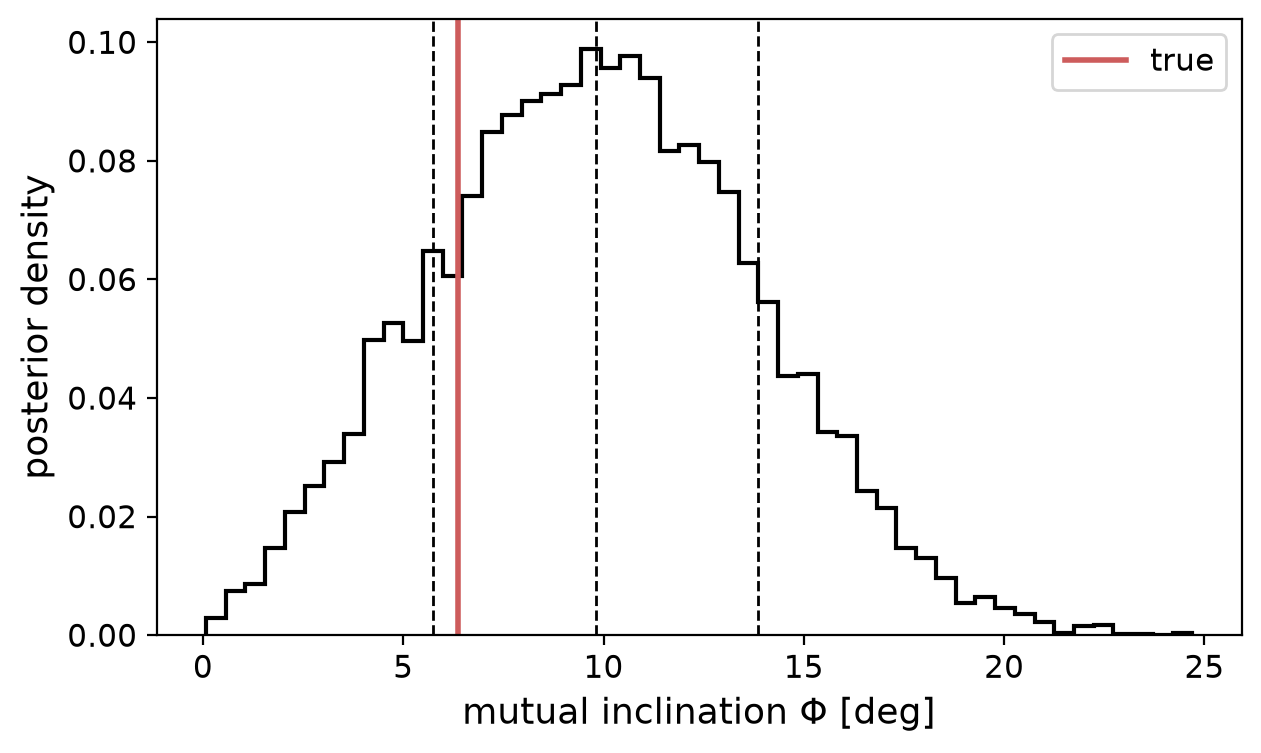

In [13]:
cos_mutual = np.cos(inc_s[0])*np.cos(inc_s[1]) + np.sin(inc_s[0])*np.sin(inc_s[1])*np.cos(Omega_s[0] - Omega_s[1])
mutual = np.degrees(np.arccos(np.clip(cos_mutual, -1, 1)))
p = planets
mutual_true = np.degrees(np.arccos(np.cos(p[0]['inc'])*np.cos(p[1]['inc']) + np.sin(p[0]['inc'])*np.sin(p[1]['inc'])*np.cos(p[0]['Omega'] - p[1]['Omega'])))

lo, med, hi, p95 = np.percentile(mutual, [16, 50, 84, 95])
print(f'mutual inclination: {med:.1f} (+{hi - med:.1f} / -{med - lo:.1f}) deg; 95% upper limit {p95:.1f} deg (true {mutual_true:.1f} deg)')

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(mutual, bins=50, histtype='step', color='k', lw=1.5, density=True)
ax.axvline(mutual_true, color='indianred', lw=2, label='true')
for q in (lo, med, hi):
    ax.axvline(q, color='k', ls='--', lw=1)
ax.set_xlabel(r'mutual inclination $\Phi$ [deg]', fontsize=13)
ax.set_ylabel('posterior density', fontsize=13)
ax.tick_params(labelsize=11)
ax.legend(fontsize=11)
plt.show()